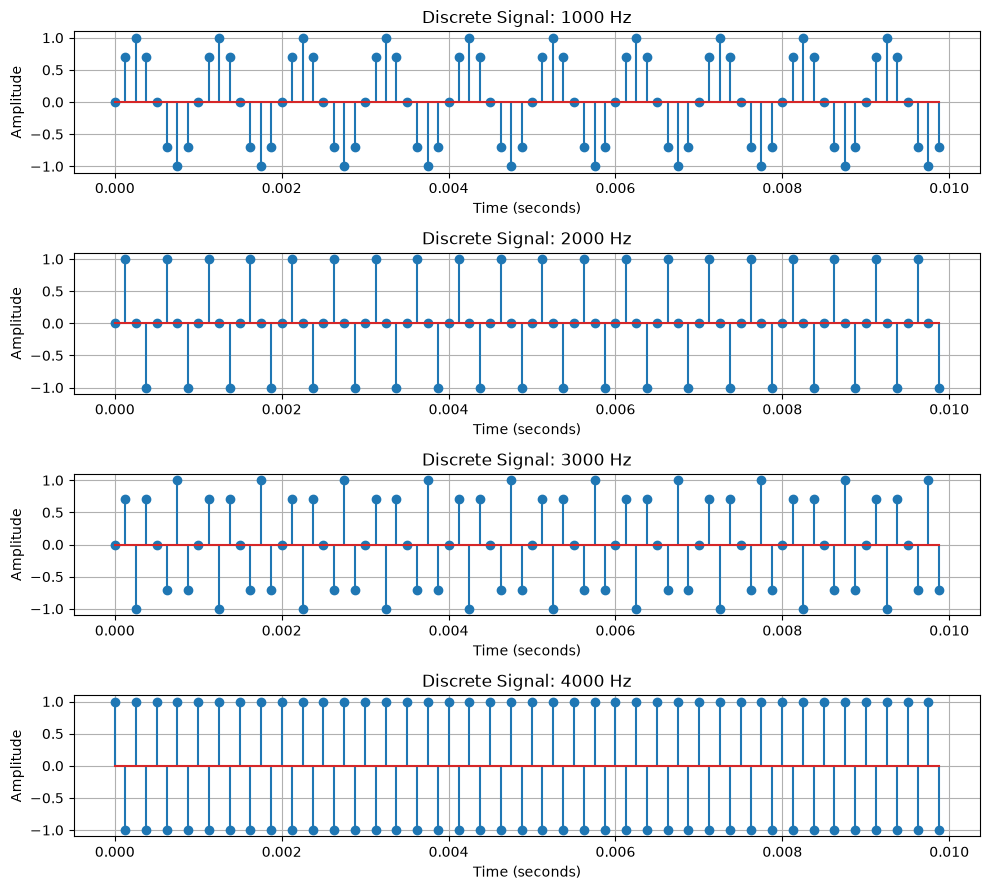

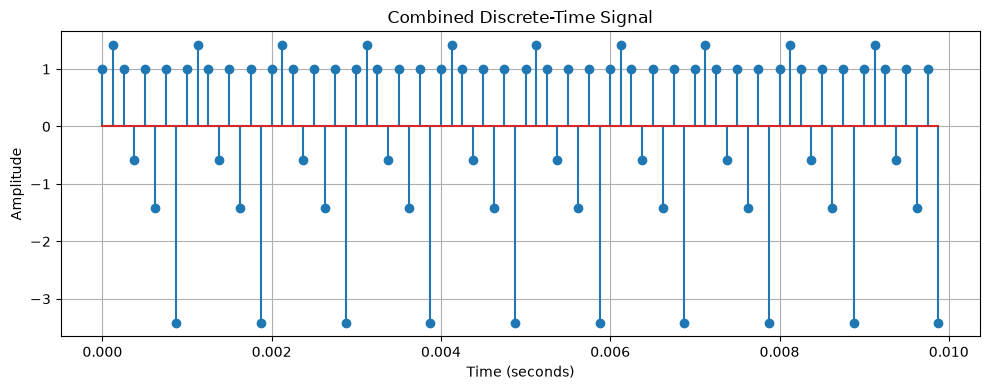

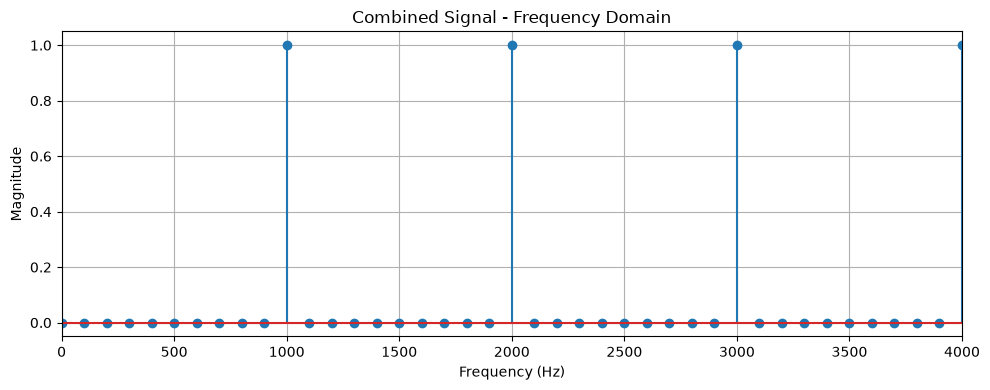

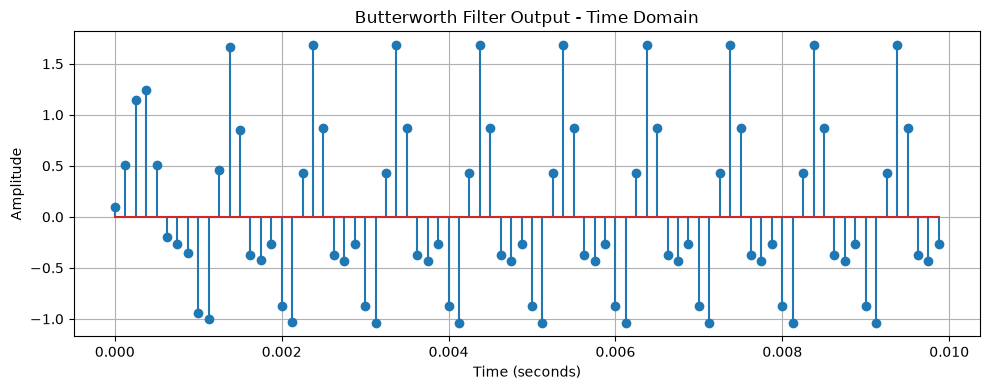

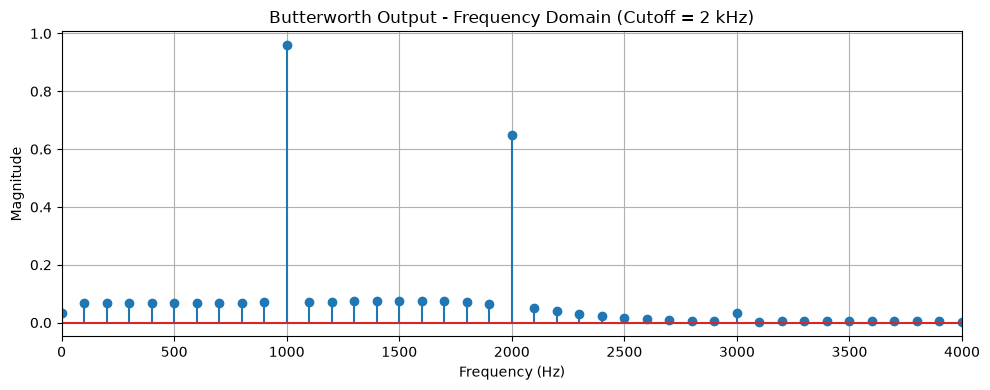

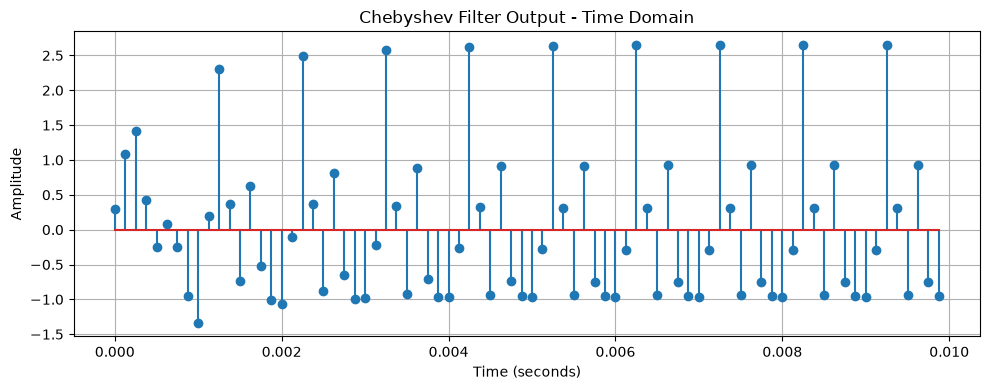

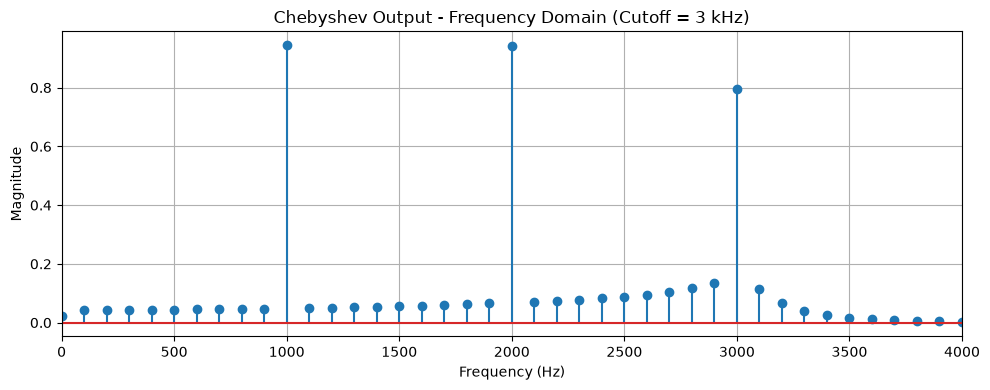

Butterworth Filter Coefficients
Numerator: [0.09398085 0.37592341 0.56388511 0.37592341 0.09398085]
Denominator: [ 1.00000000e+00 -2.49800181e-16  4.86028822e-01 -6.63518679e-17
  1.76648009e-02]

Chebyshev Type I Filter Coefficients
Numerator: [0.29503203 1.18012811 1.77019216 1.18012811 0.29503203]
Denominator: [1.         1.71305353 1.53498132 0.59289693 0.1592886 ]


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, cheby1, lfilter

# --------------------------------------------------
# 1. SIGNAL SPECIFICATIONS
# --------------------------------------------------
fs = 8000                 # Sampling frequency (Hz)
duration = 0.01            # Signal duration in seconds
t = np.arange(0, duration, 1 / fs)
N = len(t)

f1 = 1000
f2 = 2000
f3 = 3000
f4 = 4000

# --------------------------------------------------
# 2. GENERATE FOUR DISCRETE SINE WAVES
# --------------------------------------------------
x1 = np.sin(2 * np.pi * f1 * t)
x2 = np.sin(2 * np.pi * f2 * t)
x3 = np.sin(2 * np.pi * f3 * t)

# Cosine is used at Nyquist frequency so it is visible
x4 = np.cos(2 * np.pi * f4 * t)

# Plot all four discrete signals
signals = [x1, x2, x3, x4]
frequencies = [f1, f2, f3, f4]

fig, axes = plt.subplots(4, 1, figsize=(10, 9))

for ax, x, f in zip(axes, signals, frequencies):
    ax.stem(t, x)
    ax.set_title(f"Discrete Signal: {f} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. ADD ALL FOUR SIGNALS
# --------------------------------------------------
x = x1 + x2 + x3 + x4

plt.figure(figsize=(10, 4))
plt.stem(t, x)
plt.title("Combined Discrete-Time Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. FUNCTION TO PLOT FREQUENCY SPECTRUM
# --------------------------------------------------
def plot_frequency_spectrum(signal, title):
    spectrum = np.fft.rfft(signal)
    freq = np.fft.rfftfreq(len(signal), d=1 / fs)

    # Normalize magnitude
    magnitude = np.abs(spectrum) / len(signal)

    # Double positive-frequency amplitudes except DC
    # and the Nyquist-frequency bin
    if len(signal) % 2 == 0:
        magnitude[1:-1] *= 2
    else:
        magnitude[1:] *= 2

    plt.figure(figsize=(10, 4))
    plt.stem(freq, magnitude)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.xlim(0, fs / 2)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Combined signal in frequency domain
plot_frequency_spectrum(
    x, "Combined Signal - Frequency Domain"
)

# --------------------------------------------------
# 5. BUTTERWORTH DIGITAL LOW-PASS FILTER
#    CUTOFF FREQUENCY = 2000 Hz
# --------------------------------------------------
order = 4
butter_b, butter_a = butter(
    order,
    2000,
    btype="low",
    fs=fs
)

butter_output = lfilter(butter_b, butter_a, x)

# Butterworth output in time domain
plt.figure(figsize=(10, 4))
plt.stem(t, butter_output)
plt.title("Butterworth Filter Output - Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

# Butterworth output in frequency domain
plot_frequency_spectrum(
    butter_output,
    "Butterworth Output - Frequency Domain (Cutoff = 2 kHz)"
)

# --------------------------------------------------
# 6. CHEBYSHEV TYPE I DIGITAL LOW-PASS FILTER
#    CUTOFF FREQUENCY = 3000 Hz
# --------------------------------------------------
cheby_b, cheby_a = cheby1(
    order,
    0.5,                 # Passband ripple in dB
    3000,
    btype="low",
    fs=fs
)

cheby_output = lfilter(cheby_b, cheby_a, x)

# Chebyshev output in time domain
plt.figure(figsize=(10, 4))
plt.stem(t, cheby_output)
plt.title("Chebyshev Filter Output - Time Domain")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

# Chebyshev output in frequency domain
plot_frequency_spectrum(
    cheby_output,
    "Chebyshev Output - Frequency Domain (Cutoff = 3 kHz)"
)

# --------------------------------------------------
# 7. DISPLAY FILTER COEFFICIENTS
# --------------------------------------------------
print("Butterworth Filter Coefficients")
print("Numerator:", butter_b)
print("Denominator:", butter_a)

print("\nChebyshev Type I Filter Coefficients")
print("Numerator:", cheby_b)
print("Denominator:", cheby_a)